# ¿Cuánto piden por un auto usado?

Trabajo práctico de Python para Ciencia de Datos · UADE

**Integrantes** · Facundo Rodrigues, Mateo Gimenez, Lautaro Acosta, Lucas Insabralde, Matias Sevilla y Bruno Herzig.

Queremos estimar el precio publicado en USD de un auto usado con su año de fabricación y kilometraje. Cada fila corresponde a un aviso histórico de Mercado Libre Argentina. Para estimar el precio de una venta o una cotización actual harían falta otros datos.

Trabajamos con todos los avisos del CSV original que tienen condición `Usado` y moneda `USD`. Guardamos en `autos.csv` 12 columnas del archivo, con datos numéricos como año y precio y categóricos como marca y combustible. Los valores originales de esas filas incluyen los duplicados, los campos vacíos y los casos que vamos a revisar.

Para ejecutarlo, poné `TP_autos.ipynb` y `autos.csv` en la misma carpeta y abrí el notebook desde allí. En el entorno de Python necesitás `pandas`, `matplotlib` y `scikit-learn`. Ejecutá las celdas de arriba hacia abajo.

[Cars publications prices - MercadoLibreARG, Ariel Rasgido, versión 1](https://www.kaggle.com/datasets/arielras/cars-publications-prices-mercadolibrearg)

## 1. Carga y revisión inicial

Leemos `autos.csv` con pandas. El separador de columnas es el punto y coma. Revisamos cuántas filas y columnas hay, los tipos y los valores faltantes.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

original = pd.read_csv("autos.csv", sep=";")
print("Filas y columnas", original.shape)
original.info()
display(original[["brand", "model", "car_year", "km", "price"]].head())
display(original.isna().sum().rename("Faltantes").to_frame())

Filas y columnas (4047, 12)
<class 'pandas.DataFrame'>
RangeIndex: 4047 entries, 0 to 4046
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            4047 non-null   str  
 1   title         4047 non-null   str  
 2   condition     4047 non-null   str  
 3   currency      4047 non-null   str  
 4   car_year      4047 non-null   int64
 5   brand         4047 non-null   str  
 6   model         4047 non-null   str  
 7   version       4047 non-null   str  
 8   km            4047 non-null   str  
 9   price         4047 non-null   int64
 10  fuel_type     4047 non-null   str  
 11  transmission  3931 non-null   str  
dtypes: int64(2), str(10)
memory usage: 379.5 KB


,brand,model,car_year,km,price
0,Volkswagen,Gol,2014,83000 km,4300
1,Volkswagen,Gol,2010,159000 km,4700
2,Volkswagen,Gol,2009,200000 km,4500
3,Volkswagen,Gol,2007,64126 km,6500
4,Volkswagen,Gol,2012,170000 km,4700


,Faltantes
id,0
title,0
condition,0
currency,0
car_year,0
brand,0
model,0
version,0
km,0
price,0


## 2. Limpieza

El ID identifica cada aviso. Buscamos las filas que comparten un ID, los años imposibles y el aviso cuyo título indica que el importe es un anticipo. En este último caso, el texto del aviso explica por qué ese importe quedaría fuera del análisis de precios completos.

In [2]:
repetidos = original["id"].duplicated(keep=False)
display(original.loc[repetidos, ["id", "brand", "model", "car_year", "price"]])

anio_imposible = ~original["car_year"].between(1886, 2024)
display(original.loc[anio_imposible, ["id", "title", "car_year", "price"]])

menciona_anticipo = original["title"].str.contains("anticipo", case=False)
display(original.loc[menciona_anticipo, ["id", "title", "price"]])

,id,brand,model,car_year,price
3138,MLA1404982421,Ford,Ka,2017,11500
3400,MLA1404982421,Ford,Ka,2017,11500


,id,title,car_year,price
911,MLA1639157994,Chevrolet Corsa 2007 1.6 Gl Aa Dh,436673,4200


,id,title,price
2792,MLA1403304889,Fiat Uno 1.4 Way Pack Anticipo U$3400 Automoto...,3400


Los dos registros del ID repetido eran idénticos y conservamos uno solo. Quitamos el Chevrolet Corsa con año `436673` y el Fiat Uno cuyo título dice que los USD 3.400 son un anticipo. Convertimos el kilometraje de texto a número para poder calcular y graficar. La transmisión tiene faltantes y queda fuera del modelo, así que podemos conservar esos avisos. Después de limpiar quedan 4.044 filas con año, kilómetros y precio completos.

In [3]:
autos = original.drop_duplicates(subset="id").copy()
autos = autos[autos["car_year"].between(1886, 2024)].copy()
autos = autos[autos["id"] != "MLA1403304889"].copy()

autos["km"] = pd.to_numeric(autos["km"].str.replace(" km", "", regex=False), errors="coerce")

columnas_modelo = ["car_year", "km", "price"]
print("Avisos antes de limpiar", len(original))
print("Avisos después de limpiar", len(autos))
display(autos[columnas_modelo].isna().sum().rename("Faltantes").to_frame())

Avisos antes de limpiar 4047
Avisos después de limpiar 4044


,Faltantes
car_year,0
km,0
price,0


## 3. Precios y kilometraje

Los histogramas muestran dónde se concentran los precios, el kilometraje y los años. Los boxplots marcan la mediana y los cuartiles. La mitad central de los avisos está entre USD 6.100 y USD 13.000, y entre 68.000 y 141.000 km. El año mediano es 2014. El precio medio ronda USD 10.896 y supera a la mediana de USD 8.700 por la cola de precios altos.

,price,km,car_year
count,4044.000000,4044.000000,4044.000000
mean,10896.214886,106858.897873,2013.844708
std,7453.779457,62226.857043,5.384602
min,1100.000000,500.000000,1990.000000
25%,6100.000000,68000.000000,2011.000000
50%,8700.000000,101000.000000,2014.000000
75%,13000.000000,141000.000000,2018.000000
max,82000.000000,999999.000000,2024.000000


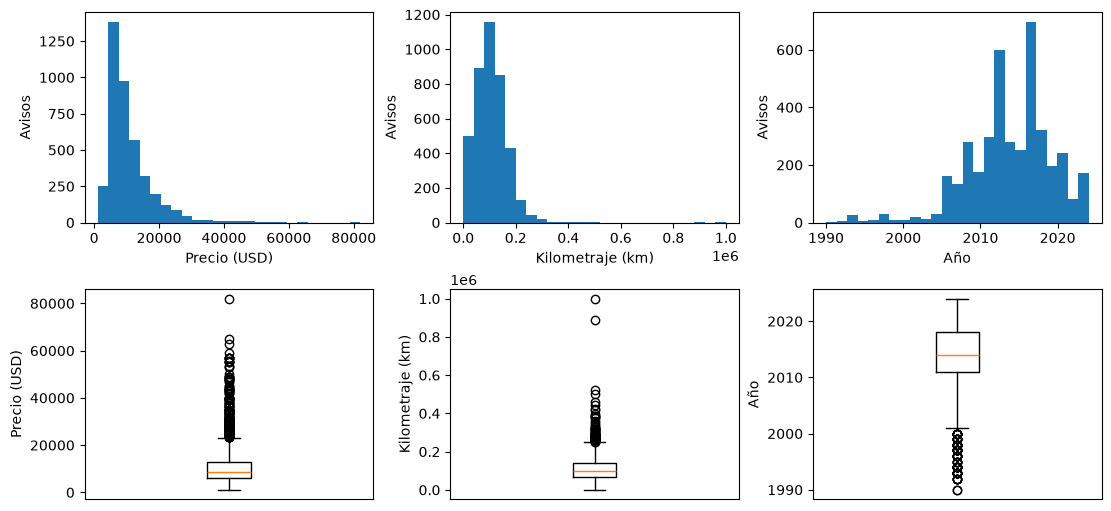

In [4]:
display(autos[["price", "km", "car_year"]].describe())

figura, ejes = plt.subplots(2, 3, figsize=(11, 5), layout="constrained")
variables = [("price", "Precio (USD)"), ("km", "Kilometraje (km)"), ("car_year", "Año")]

for i, (columna, etiqueta) in enumerate(variables):
    ejes[0, i].hist(autos[columna], bins=25)
    ejes[0, i].set(xlabel=etiqueta, ylabel="Avisos")
    ejes[1, i].boxplot(autos[columna])
    ejes[1, i].set(ylabel=etiqueta, xticks=[])

plt.show()

## 4. Relación entre variables

Cada punto es un aviso. Comparamos el precio con el año y los kilómetros. El precio tiende a subir en autos más nuevos (correlación de Pearson de 0,59) y a bajar cuando aumenta el kilometraje (−0,51). En los gráficos, autos con el mismo año o kilometraje pueden tener precios muy distintos. El año del vehículo describe su fabricación. Para graficar una serie de precios harían falta fechas de publicación.

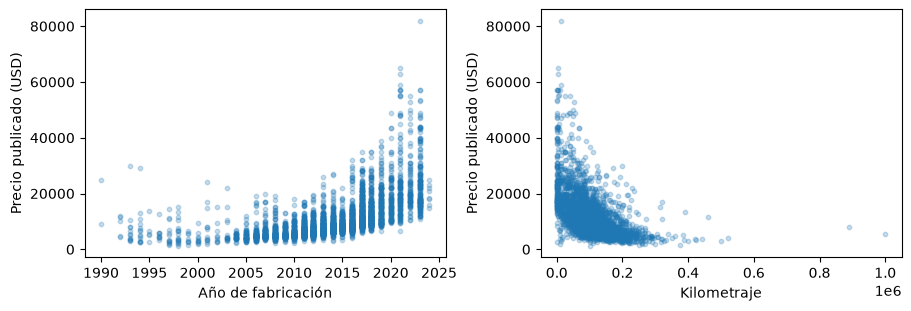

,car_year,km,price
car_year,1.000000,-0.609257,0.590185
km,-0.609257,1.000000,-0.513718
price,0.590185,-0.513718,1.000000


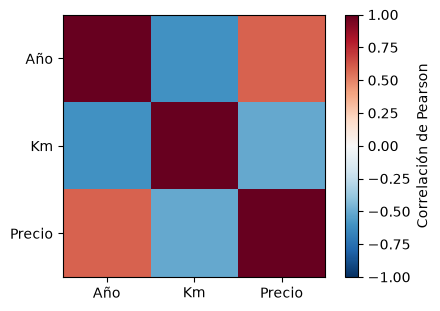

In [5]:
figura, ejes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
autos.plot.scatter(x="car_year", y="price", ax=ejes[0], alpha=0.25, s=10)
autos.plot.scatter(x="km", y="price", ax=ejes[1], alpha=0.25, s=10)
for eje in ejes:
    eje.set_ylabel("Precio publicado (USD)")
ejes[0].set_xlabel("Año de fabricación")
ejes[1].set_xlabel("Kilometraje")
plt.show()

correlaciones = autos[["car_year", "km", "price"]].corr()
display(correlaciones)
figura, eje = plt.subplots(figsize=(5, 3), layout="constrained")
imagen = eje.imshow(correlaciones, vmin=-1, vmax=1, cmap="RdBu_r")
eje.set_xticks([0, 1, 2], ["Año", "Km", "Precio"])
eje.set_yticks([0, 1, 2], ["Año", "Km", "Precio"])
figura.colorbar(imagen, ax=eje, label="Correlación de Pearson")
plt.show()

## 5. Precio por marca

Agrupamos los avisos por marca con `groupby`. Usamos la mediana para comparar el precio típico y la cantidad para saber cuántos avisos hay detrás de cada barra. Toyota tiene la mediana más alta de la muestra (USD 17.725 en 428 avisos). Cada marca reúne autos de varios modelos y edades, así que la comparación describe los avisos observados.

,avisos,mediana_usd
brand,,
Chevrolet,460,6550.0
Fiat,480,7000.0
Peugeot,750,7000.0
Renault,390,7800.0
Volkswagen,797,9000.0
Ford,576,10000.0
Honda,163,12500.0
Toyota,428,17725.0


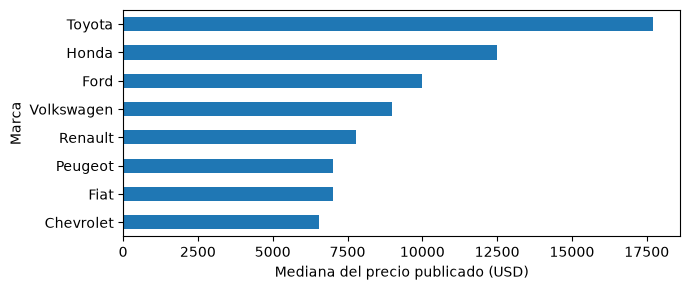

In [6]:
por_marca = autos.groupby("brand")["price"].agg(
    avisos="size", mediana_usd="median"
).sort_values("mediana_usd")

display(por_marca)
eje = por_marca["mediana_usd"].plot.barh(figsize=(7, 3))
eje.set_xlabel("Mediana del precio publicado (USD)")
eje.set_ylabel("Marca")
plt.tight_layout()
plt.show()

## 6. Entrenamiento y prueba

Elegimos el año y el kilometraje porque son datos disponibles en la ficha de un auto usado. Esas dos columnas forman `X`. El precio publicado forma `y`. Para mantener juntas las fichas de una misma configuración, armamos una clave con marca, modelo, versión y año. Reservamos un 20 % de las claves para prueba. La proporción de filas depende del tamaño de cada grupo.

In [7]:
from sklearn.model_selection import train_test_split

columnas_grupo = ["brand", "model", "version", "car_year"]
grupo = autos[columnas_grupo].astype(str).agg(" | ".join, axis=1).str.lower()

grupos_train, grupos_test = train_test_split(
    grupo.unique(), test_size=0.20, random_state=42
)

train = autos[grupo.isin(grupos_train)]
test = autos[grupo.isin(grupos_test)]

X_train = train[["car_year", "km"]]
y_train = train["price"]
X_test = test[["car_year", "km"]]
y_test = test["price"]

print("Avisos de entrenamiento", len(train))
print("Avisos de prueba", len(test))
print("Grupos compartidos", len(set(grupos_train) & set(grupos_test)))

Avisos de entrenamiento 3213
Avisos de prueba 831
Grupos compartidos 0


## 7. Regresión lineal y evaluación

La referencia predice siempre la mediana de los precios de entrenamiento. La regresión lineal aprende a combinar año y kilometraje usando esas mismas filas. Reservamos el conjunto de prueba para comparar las predicciones al final.

El MAE es la diferencia absoluta promedio en USD. El RMSE da más peso a los errores grandes. Un R² cercano a 1 indica mejor ajuste en prueba.

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

modelo = LinearRegression()
modelo.fit(X_train, y_train)
prediccion = modelo.predict(X_test)
referencia = [y_train.median()] * len(y_test)

resultados = []
for nombre, estimaciones in [("Mediana de train", referencia), ("Regresión lineal", prediccion)]:
    resultados.append({
        "Modelo": nombre,
        "MAE (USD)": mean_absolute_error(y_test, estimaciones),
        "RMSE (USD)": root_mean_squared_error(y_test, estimaciones),
        "R²": r2_score(y_test, estimaciones),
    })

metricas = pd.DataFrame(resultados).set_index("Modelo")
display(metricas)

,MAE (USD),RMSE (USD),R²
Modelo,,,
Mediana de train,5502.448857,9523.423934,-0.138390
Regresión lineal,4479.196837,7198.346241,0.349615


## 8. Conclusiones

El precio mediano de la muestra es USD 8.700. La regresión redujo el MAE de prueba de USD 5.502,45 a USD 4.479,20, una mejora de alrededor del 19 % frente a la mediana de entrenamiento. El RMSE fue de USD 7.198,35 y el R² de 0,35.

Los tres errores más grandes corresponden a Toyota Yaris de 2021 cuyo precio publicado era mucho mayor que el estimado. Con solo año y kilómetros, dos autos de distinto modelo o estado pueden recibir estimaciones parecidas. Para una próxima versión probaríamos incorporar marca, modelo y estado del vehículo.

In [9]:
mae_referencia = metricas.loc["Mediana de train", "MAE (USD)"]
mae_lineal = metricas.loc["Regresión lineal", "MAE (USD)"]

print("Precio mediano de la muestra en USD", autos["price"].median())
print("MAE de la referencia en USD", mae_referencia)
print("MAE de la regresión en USD", mae_lineal)

errores = test[["brand", "model", "car_year", "km", "price"]].copy()
errores["estimado_usd"] = prediccion
errores["error_absoluto_usd"] = (errores["price"] - errores["estimado_usd"]).abs()
display(errores.nlargest(3, "error_absoluto_usd"))

Precio mediano de la muestra en USD 8700.0
MAE de la referencia en USD 5502.4488567990375
MAE de la regresión en USD 4479.196837284912


,brand,model,car_year,km,price,estimado_usd,error_absoluto_usd
3830,Toyota,Yaris,2021,3000,63000,17680.158699,45319.841301
3832,Toyota,Yaris,2021,13000,59000,17424.024381,41575.975619
3831,Toyota,Yaris,2021,9000,57000,17526.478108,39473.521892
